# 4.1 Recap: Train and Save a Model

This notebook revisits the familiar machine-learning workflow and creates the artifact used by the deployment example:

1. load and inspect data,
2. split features and targets,
3. combine preprocessing and classification in a pipeline,
4. train and evaluate the pipeline,
5. serialize the complete pipeline for the FastAPI backend.

The Iris dataset keeps the deployment example intentionally small: the model receives four numeric flower measurements and predicts one of three Iris species.

In [ ]:
# %pip joblib fastapi uvicorn[standard] streamlit requests httpx2

In [ ]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
  ConfusionMatrixDisplay,
  accuracy_score,
  classification_report,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'backend').exists():
  candidate = PROJECT_DIR / '04_Solution_4'
  if candidate.exists():
    PROJECT_DIR = candidate

ARTIFACT_PATH = PROJECT_DIR / 'artifacts' / 'iris_pipeline.joblib'
print(f'Project directory: {PROJECT_DIR.resolve()}')

## Load and inspect the Iris dataset

Scikit-learn provides the dataset locally. `as_frame=True` returns labeled pandas objects, which makes the four input features and target easier to inspect.

In [2]:
iris = load_iris(as_frame=True)
data = iris.frame
feature_names = list(iris.feature_names)
target_names = list(iris.target_names)

data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [3]:
print(f'Shape: {data.shape}')
print(f'Features: {feature_names}')
print(f'Classes: {target_names}')
data['target'].value_counts().sort_index()

Shape: (150, 5)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


target
0    50
1    50
2    50
Name: count, dtype: int64

## Split the data

`stratify=y` preserves the class proportions in the training and test sets. The untouched test set is used only for the final evaluation.

In [4]:
X = data[feature_names]
y = data['target']

X_train, X_test, y_train, y_test = train_test_split(
  X,
  y,
  test_size=0.2,
  random_state=RANDOM_STATE,
  stratify=y,
)

print(f'Training samples: {len(X_train)}')
print(f'Test samples: {len(X_test)}')

Training samples: 120
Test samples: 30


## Build and train one pipeline

The scaler and classifier are stored in a single `Pipeline`. This is important for deployment: the backend must apply exactly the same preprocessing that was learned during training.

In [5]:
pipeline = Pipeline([
  ('scaler', StandardScaler()),
  (
    'classifier',
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
  ),
])

pipeline.fit(X_train, y_train)
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal length (cm)','sepal width (cm)','petal length (cm)', 'petal width (cm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Evaluate the trained pipeline

In [6]:
y_pred = pipeline.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f'Test accuracy: {accuracy:.3f}')
print()
print(classification_report(y_test, y_pred, target_names=target_names))

Test accuracy: 0.933

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



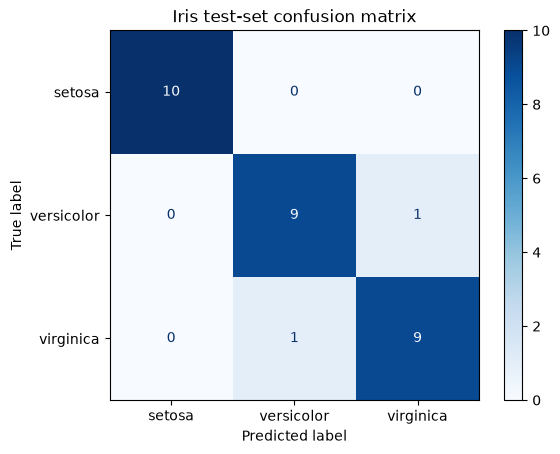

In [7]:
ConfusionMatrixDisplay.from_predictions(
  y_test,
  y_pred,
  display_labels=target_names,
  cmap='Blues',
)
plt.title('Iris test-set confusion matrix')
plt.show()

## Inspect one prediction

The backend will later receive these four values as JSON. The pipeline converts them to the same representation used during training.

In [8]:
example = X_test.iloc[[0]].copy()
display(example)
predicted_target = int(pipeline.predict(example)[0])
probabilities = pipeline.predict_proba(example)[0]

print(f'Predicted class: {target_names[predicted_target]}')
for class_name, probability in zip(target_names, probabilities):
  print(f'{class_name}: {probability:.1%}')

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
38,4.4,3.0,1.3,0.2


Predicted class: setosa
setosa: 97.9%
versicolor: 2.1%
virginica: 0.0%


## Save the deployment artifact

The artifact contains the fitted pipeline and the metadata required to turn numeric model outputs into readable API responses. Only trusted local artifacts should be loaded with Joblib.

In [ ]:
artifact = {
  'pipeline': pipeline,
  'feature_names': feature_names,
  'target_names': target_names,
}

ARTIFACT_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(artifact, ARTIFACT_PATH)
print(f'Saved artifact to: {ARTIFACT_PATH.resolve()}')

In [10]:
loaded_artifact = joblib.load(ARTIFACT_PATH)
loaded_prediction = int(loaded_artifact['pipeline'].predict(example)[0])
assert loaded_prediction == predicted_target
print('Reload check successful.')

Reload check successful.


The serialized pipeline is now the contract between model development and deployment. Continue with `backend/4_2_FastAPI_Backend.ipynb`.